# Committor Model: 1D Low-Friction Langevin Dynamics, with History

Trains a non-parametric committor (`CommittorNE`) on a long underdamped Langevin trajectory of a particle in 1D. At low friction the committor depends on position and velocity, q(λ, v), but only λ is given to the model. The velocity enters through the history: with lag d = 1 the basis is a polynomial in (λ(t−1), λ(t)), and with one frame per MD step that is equivalent to λ and the finite-difference velocity (λ(t) − λ(t−1))/dt.

**Data:** `md_istarwell2_100M/md_path.npy` (100M frames, one per step of dt = 0.005, columns λ and v; converted from `md_path.txt`). Friction γ = 1, kT = 1, m = 1.

**Potential:** `CosWellWalls`, a well of depth 1.2 kT on [−0.25, 0.25], flanked by 0.15 kT bumps and flat regions, with harmonic walls (k = 100) beyond ±0.45.

**Boundaries:** `λ <= -0.35` (A) and `λ >= 0.35` (B), the outer iSTAR interfaces

## 1. Imports

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package
import sys
sys.path.insert(0, '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/')
import optimalrcs, metrics, plots

## 2. Data Loading

Loads the first `n_frames` frames (5M frames contain about 8000 A↔B transitions). The velocity `v` is only used to check the result in section 6, not in training.

In [7]:
SRC = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/md_istarwell2_100M'
n_frames = 6_000_000

data = np.load(f'{SRC}/md_path.npy', mmap_mode='r')[:n_frames]
lam, v = np.array(data[:, 0]), np.array(data[:, 1])
lambda_a, lambda_b = -0.35, 0.35
dt = 0.005                         # MD time step = time per frame
print(f'Frames: {len(lam)}')

Frames: 6000000


## 3. Free Energy Profile (FEP)

FEP along λ: the central well between the two small bumps.

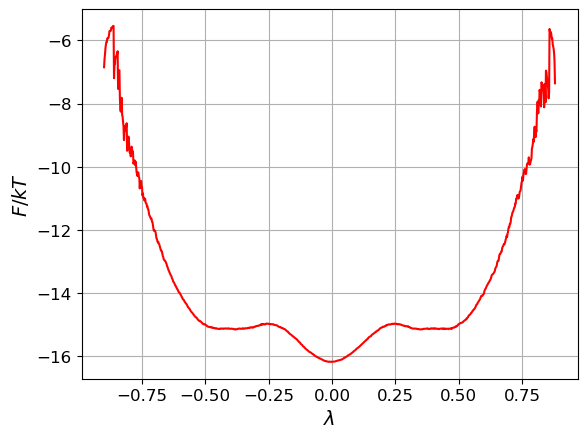

In [8]:
fig, ax = plt.subplots(1, 1)
plots.plot_fep(ax, cp.asarray(lam), xlabel='$\\lambda$')
plt.show()

## 4. Trajectory Indices

Single trajectory (`i_traj = 1` for all frames).

In [9]:
i_traj = np.ones_like(lam)          # trajectory index (1 = single trajectory)
t_traj = np.arange(len(lam))        # frame index

## 5. Train Committor (Non-Parametric), Several Seeds

`CommittorNE` rather than the equilibrium `Committor`: time reversal flips the velocity, so the reversible estimator does not apply to q(λ, v). The CVs are λ and the recorded velocity v; each iteration draws one of them.

The fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). Each fit runs in chunks of `CHUNK` iterations; after every chunk the metrics, FEPs + Z_q and observed-vs-predicted plots and the (λ, v) map are saved to `figures/langevin_seeds/seed<s>/it<N>_*.png`, and the error against the brute-force reference q(x, v) is printed. `fit_transform` continues from the current RC on every call, so the chunks form one continuous run.

`lazy_basis=True` evaluates the basis in fused GPU kernels: about 4× faster here, same result. It is used instead of fewer frames: the statistical error of the comparison grows from 0.012 per bin at 6M frames to 0.020 at 2M.

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `SEEDS` | 0, 1, 2 | Random seeds |
| `MAX_ITER` | 30000 | Iterations per seed |
| `CHUNK` | 5000 | Iterations between saved plots |
| `envelope_scale` | 0.001 | RC envelope width |
| `gamma` | 0.1 | Regularization (scales the step; does not change the fixed point) |
| `ny` | 6 | Polynomial degree |

#=500, xent=0.403296, mse=0.140371, sdzq=386.19, dzq=1308.56, dr2=11145.1, auc=0.869933, |dx|=0.206337, time=12.6336
#=1000, xent=0.400811, mse=0.140252, sdzq=360.309, dzq=1202.67, dr2=11116.6, auc=0.870188, |dx|=0.00296253, time=25.2785
#=1500, xent=0.402351, mse=0.140193, sdzq=342.662, dzq=1137.76, dr2=11144.2, auc=0.870257, |dx|=0.00161196, time=37.9158
#=2000, xent=0.400552, mse=0.140148, sdzq=336.27, dzq=1098.41, dr2=11133.3, auc=0.870426, |dx|=0.00142694, time=50.5648


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3374659/1071906375.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 21, warmup iterations: RMS(fit - exact) per frame 0.0512, plots in figures/langevin_seeds/seed21
#=3000, xent=0.3976, mse=0.139073, sdzq=208.281, dzq=474.318, dr2=10942.2, auc=0.873086, |dx|=0.0276838, time=23.9315
#=4000, xent=0.397394, mse=0.13905, sdzq=208.181, dzq=474.155, dr2=10917.8, auc=0.873167, |dx|=0.00213139, time=47.8746
#=5000, xent=0.397304, mse=0.139021, sdzq=205.425, dzq=469.854, dr2=10903.4, auc=0.873216, |dx|=0.00176432, time=71.8267
#=6000, xent=0.397211, mse=0.139007, sdzq=205.193, dzq=469.475, dr2=10894.7, auc=0.873249, |dx|=0.00114254, time=95.8163
#=7000, xent=0.397194, mse=0.138994, sdzq=204.783, dzq=468.504, dr2=10889.4, auc=0.873278, |dx|=0.000871939, time=119.81


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3374659/1071906375.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 21, 5000 iterations: RMS(fit - exact) per frame 0.0330, plots in figures/langevin_seeds/seed21
#=8000, xent=0.39731, mse=0.138993, sdzq=203.927, dzq=467.661, dr2=10891.4, auc=0.873282, |dx|=0.000646046, time=23.9638
#=9000, xent=0.397202, mse=0.138983, sdzq=203.842, dzq=467.071, dr2=10881.3, auc=0.8733, |dx|=0.000605997, time=47.9865
#=10000, xent=0.397245, mse=0.13898, sdzq=204.454, dzq=467.503, dr2=10881.6, auc=0.873306, |dx|=0.000561104, time=71.9971
#=11000, xent=0.397124, mse=0.138976, sdzq=203.786, dzq=466.874, dr2=10876.2, auc=0.873315, |dx|=0.00034016, time=96.0105
#=12000, xent=0.397119, mse=0.138972, sdzq=203.76, dzq=466.473, dr2=10874.7, auc=0.873325, |dx|=0.00035484, time=120.035


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3374659/1071906375.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


... (6 outputs left out)

seed 23, 5000 iterations: RMS(fit - exact) per frame 0.0328, plots in figures/langevin_seeds/seed23
#=8000, xent=0.39719, mse=0.138981, sdzq=204.526, dzq=468.552, dr2=10884.4, auc=0.873294, |dx|=0.000422725, time=24.304
#=9000, xent=0.397201, mse=0.138982, sdzq=204.181, dzq=468.353, dr2=10883.9, auc=0.873304, |dx|=0.000909712, time=48.3571
#=10000, xent=0.397109, mse=0.138974, sdzq=204.256, dzq=468.515, dr2=10876, auc=0.873317, |dx|=0.000522302, time=72.4325
#=11000, xent=0.397125, mse=0.138969, sdzq=204.286, dzq=468.262, dr2=10874, auc=0.873326, |dx|=0.00045747, time=96.4653
#=12000, xent=0.397087, mse=0.138963, sdzq=203.968, dzq=467.745, dr2=10869.2, auc=0.873335, |dx|=0.000362042, time=120.486


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3374659/1071906375.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')


seed 23, 10000 iterations: RMS(fit - exact) per frame 0.0325, plots in figures/langevin_seeds/seed23
#=13000, xent=0.39711, mse=0.138965, sdzq=204.173, dzq=467.76, dr2=10869.4, auc=0.873338, |dx|=0.000521906, time=24.0207
#=14000, xent=0.397074, mse=0.138963, sdzq=204.269, dzq=468.095, dr2=10866.2, auc=0.873346, |dx|=0.000351757, time=48.1769

Training interrupted at iteration 14251; keeping the RC of the last completed update.


KeyboardInterrupt: 

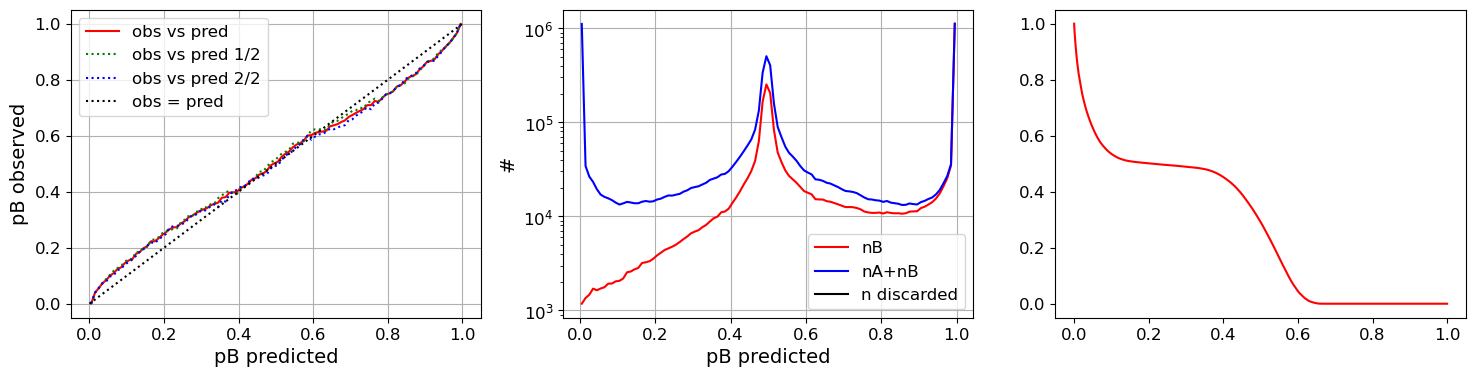

In [15]:
import os
from scipy.interpolate import RegularGridInterpolator

SEEDS = [21, 23]
MAX_ITER = 15000
CHUNK = 5000
OUT = 'figures/langevin_seeds'

gamma = 0                      # regularization strength
Y = cp.asarray(np.c_[lam, v])      # CVs: lambda and the recorded velocity
history=[0,1]
yr_type=['y(t-d),y(t)']

# brute-force reference q(x, v), for the progress printout
ref = np.load('figures/well_check/reference.npz')
f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[np.clip(lam, ref['xs'][0], ref['xs'][-1]), np.clip(v, ref['vs'][0], ref['vs'][-1])]), 0, 1)
free = (lam > lambda_a) & (lam < lambda_b)
edges_l, edges_v = np.linspace(lambda_a, lambda_b, 71), np.linspace(-3, 3, 61)
n_lv = np.histogram2d(lam, v, [edges_l, edges_v])[0]

def save_plots(q, folder, tag):
    # the library's plot methods call plt.show(); keep the figures open to save them instead
    show, plt.show = plt.show, (lambda *a, **k: None)
    try:
        q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
        plt.gcf().savefig(f'{folder}/{tag}_metrics.png', dpi=100); plt.close('all')
        q.plots_feps(delta_t_sim=dt)
        plt.gcf().savefig(f'{folder}/{tag}_feps.png', dpi=100); plt.close('all')
        q.plots_obs_pred()
        plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100); plt.close('all')
        r = cp.asnumpy(q.r_traj)
        s = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)[0]
        fig, ax = plt.subplots(figsize=(7, 5))
        im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s / np.maximum(n_lv, 1), np.nan).T,
                           cmap='coolwarm', vmin=0, vmax=1)
        fig.colorbar(im, ax=ax, label='$q$'); ax.set(xlabel='$\\lambda$', ylabel='$v$', title=tag)
        fig.savefig(f'{folder}/{tag}_q_lambda_v.png', dpi=100); plt.close('all')
    finally:
        plt.show = show
    return r

results = {}
for seed in SEEDS:
    folder = f'{OUT}/seed{seed}'
    os.makedirs(folder, exist_ok=True)
    np.random.seed(seed); cp.random.seed(seed)
    q = optimalrcs.CommittorNE(
        boundary0=lam <= lambda_a,     # state A
        boundary1=lam >= lambda_b,     # state B
        i_traj=i_traj,
        t_traj=t_traj,
    )
    optimalrcs.envelope_scale=1000000
    q.fit_transform(
        lambda: lam,
        # lambda: Y[:, np.random.randint(2)],
        gamma=gamma,
        max_iter=2000,
        print_step=500,
        save_min_delta_zq=False,
        history_delta_t=history,
        history_type=yr_type, history_shift_type='r(t)',delta_r2_max_change_allowed=10000,
        lazy_basis=True,
    )
    r = save_plots(q, folder, f'it_warmup')
    rms = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
    print(f'seed {seed}, warmup iterations: RMS(fit - exact) per frame {rms:.4f}, plots in {folder}', flush=True)
    for done in range(CHUNK, MAX_ITER + 1, CHUNK):
        optimalrcs.envelope_scale = 0.01
        q.fit_transform(
            lambda: lam,
            # lambda: Y[:, np.random.randint(2)],
            gamma=gamma,
            max_iter=CHUNK,
            print_step=1000,
            save_min_delta_zq=False,
            history_delta_t=history,
            history_type=yr_type, history_shift_type='r(t)',
            lazy_basis=True,
        )
        r = save_plots(q, folder, f'it{done}')
        rms = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
        print(f'seed {seed}, {done} iterations: RMS(fit - exact) per frame {rms:.4f}, plots in {folder}', flush=True)
    np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
    results[seed] = r

# Diagnostics of the last seed
q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
plt.show()
q.plots_feps(delta_t_sim=dt)
q.plots_obs_pred()

## 6. Committor in the (λ, v) Plane

Mean q per (λ, v) bin, using the true velocity from the MD. If the history captured the velocity, q depends on v and not only on λ: particles moving towards B have higher q.

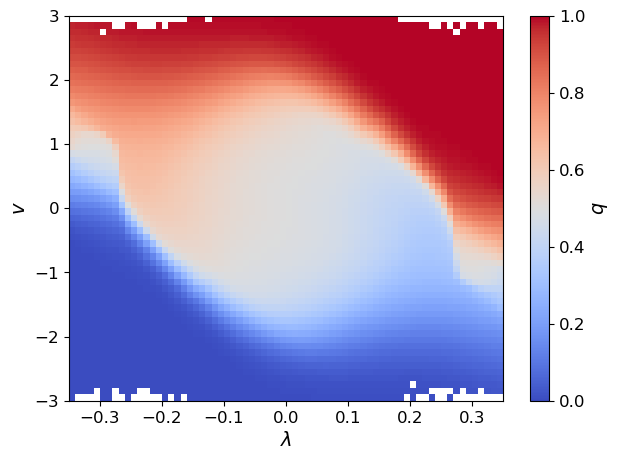

In [6]:
r = cp.asnumpy(q.r_traj)
edges_l = np.linspace(lambda_a, lambda_b, 71)
edges_v = np.linspace(-3, 3, 61)
n, _, _ = np.histogram2d(lam, v, [edges_l, edges_v])
s, _, _ = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)
q_lv = np.where(n > 20, s / np.maximum(n, 1), np.nan)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
im = ax.pcolormesh(edges_l, edges_v, q_lv.T, cmap='coolwarm', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='$q$')
ax.set(xlabel='$\\lambda$', ylabel='$v$')
plt.show()

## 7. Save Results

Uncomment to save the raw committor trajectory to disk.

In [9]:
np.save('q_traj_langevin_env0.001g0.2.npy', cp.asnumpy(q.r_traj))